# Online Retail II — EDA v3 (Plan D: churn / repurchase)

**Positive class (unified):** `churn = at-risk customer (bought within prior 180d) makes NO purchase in next `HORIZON_DAYS``.

> v3 fixes: clustered-bootstrap CI for the rolling panel (repeated customers aren't independent), H-sensitivity across all cutoffs, customer revenue-concentration check, richer seasonality, accurate split title, explicit K-means feature prohibition. Loads via `ds_common`.


## Setup


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ds_common import *
events = load_events(); lines = load_clean_lines()
T0="event_time"; LOOKBACK=180; maxd=events[T0].max()
events=events.sort_values([KEY,T0])
rng=np.random.default_rng(RANDOM_SEED)

def wilson(k,n,z=1.96):
    if n==0: return (np.nan,np.nan)
    p=k/n; d=1+z*z/n; c=(p+z*z/(2*n))/d; h=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return round((c-h)*100,2), round((c+h)*100,2)

def clustered_bootstrap_ci(df, group_col, val_col, B=400):
    """95% CI resampling GROUPS (customers), keeping all their rows — respects non-independence."""
    groups={g:sub[val_col].values for g,sub in df.groupby(group_col)}
    keys=np.array(list(groups)); rates=[]
    for _ in range(B):
        samp=rng.choice(keys,size=len(keys),replace=True)
        rates.append(np.concatenate([groups[g] for g in samp]).mean())
    lo,hi=np.percentile(rates,[2.5,97.5]); return round(lo*100,2), round(hi*100,2)
print("HORIZON_DAYS", HORIZON_DAYS, "| LOOKBACK", LOOKBACK, "| max", maxd.date())


loaded events.pkl: 36,316 rows x 6 cols | saved 2026-07-02 15:09
loaded clean_lines.pkl: 770,551 rows x 10 cols | saved 2026-07-02 15:09
HORIZON_DAYS 90 | LOOKBACK 180 | max 2011-12-09


## 0.5 Data quality — null rates & outliers (tables)
`clean_lines` is now the **netted, Customer-ID-only** line table (0 nulls by construction); `events` must be fully non-null. Outliers via IQR.


In [2]:
def outlier_table(df, cols):
    rows=[]
    for c in cols:
        s=df[c].dropna().astype(float); q1,q3=s.quantile([.25,.75]); iqr=q3-q1
        lo,hi=q1-1.5*iqr,q3+1.5*iqr; n=int(((s<lo)|(s>hi)).sum())
        rows.append({"col":c,"mean":round(s.mean(),2),"std":round(s.std(),2),"min":s.min(),
                     "Q1":q1,"median":s.median(),"Q3":q3,"max":s.max(),"n_outlier_IQR":n,"outlier_%":round(n/len(s)*100,2)})
    return pd.DataFrame(rows)
print("NULL RATES — clean_lines (now CID-only, expect 0):")
display(pd.DataFrame({"n_missing":lines.isna().sum(),"missing_%":lines.isna().mean().mul(100).round(2),"dtype":lines.dtypes.astype(str)}))
print("NULL RATES — events:")
display(pd.DataFrame({"n_missing":events.isna().sum(),"missing_%":events.isna().mean().mul(100).round(2)}))
print("OUTLIERS — clean_lines:"); display(outlier_table(lines,[QTY,PRICE,"line_revenue"]))
print("OUTLIERS — events:"); display(outlier_table(events,["n_items","basket_qty","basket_value"]))


NULL RATES — clean_lines (now CID-only, expect 0):


,n_missing,missing_%,dtype
Invoice,0,0.0,object
StockCode,0,0.0,object
Description,0,0.0,object
Quantity,0,0.0,int64
InvoiceDate,0,0.0,datetime64[ns]
Price,0,0.0,float64
Customer ID,0,0.0,int64
Country,0,0.0,object
source_sheet,0,0.0,object
line_revenue,0,0.0,float64


NULL RATES — events:


,n_missing,missing_%
Customer ID,0,0.0
Invoice,0,0.0
event_time,0,0.0
n_items,0,0.0
basket_qty,0,0.0
basket_value,0,0.0


OUTLIERS — clean_lines:


,col,mean,std,min,Q1,median,Q3,max,n_outlier_IQR,outlier_%
0,Quantity,13.04,72.31,1.00,2.00,6.00,12.00,19152.0,50064,6.50
1,Price,2.91,4.03,0.03,1.25,1.95,3.75,649.5,61879,8.03
2,line_revenue,21.20,65.10,0.06,4.95,11.90,19.50,8925.0,62109,8.06


OUTLIERS — events:


,col,mean,std,min,Q1,median,Q3,max,n_outlier_IQR,outlier_%
0,n_items,20.93,22.37,1.00,7.0000,15.00,27.0000,540.0,2108,5.80
1,basket_qty,276.70,989.61,1.00,73.0000,152.00,286.0000,87167.0,2681,7.38
2,basket_value,449.90,908.77,0.38,156.8675,298.48,466.0975,43555.1,2844,7.83


## 1. Purchase frequency (95% Wilson CI on repeat rate)


purchases/customer median: 3 mean: 6.22 max: 370
repeat (>=2): 4225/5839 = 72.4%  Wilson95=(np.float64(71.2), np.float64(73.49))


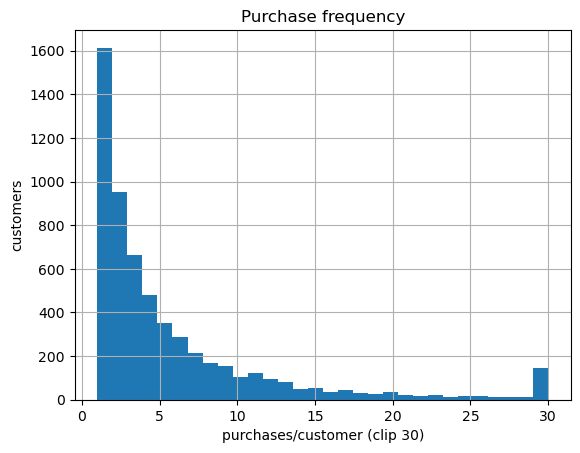

In [3]:
ppc=events.groupby(KEY).size(); n=len(ppc); rep=int((ppc>=2).sum())
print("purchases/customer median:",int(ppc.median()),"mean:",round(ppc.mean(),2),"max:",int(ppc.max()))
print(f"repeat (>=2): {rep}/{n} = {rep/n*100:.1f}%  Wilson95={wilson(rep,n)}")
plt.figure(); ppc.clip(upper=30).hist(bins=30); plt.title("Purchase frequency"); plt.xlabel("purchases/customer (clip 30)"); plt.ylabel("customers"); plt.show()


## 2. Inter-purchase gap — per customer


pooled median: 25.0 d (biased by frequent buyers)
per-customer median-of-medians: 57.0 d  <- per-customer statistic (not pooled)
country mix: {'United Kingdom': 0.901, 'Germany': 0.02, 'EIRE': 0.02}  (~90% UK here; ~92% raw)


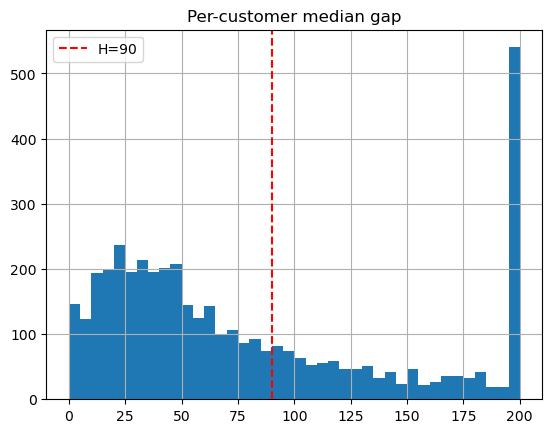

In [4]:
g=events.assign(gap=lambda x:x.groupby(KEY)[T0].diff().dt.days)
print("pooled median:",g["gap"].median(),"d (biased by frequent buyers)")
print("per-customer median-of-medians:",round(g.groupby(KEY)["gap"].median().median(),1),"d  <- per-customer statistic (not pooled)")
print("country mix:",lines[COUNTRY].value_counts(normalize=True).head(3).round(3).to_dict()," (~90% UK here; ~92% raw)")
plt.figure(); g.groupby(KEY)["gap"].median().dropna().clip(upper=200).hist(bins=40)
plt.axvline(HORIZON_DAYS,color="red",ls="--",label=f"H={HORIZON_DAYS}"); plt.legend(); plt.title("Per-customer median gap"); plt.show()


## 3. Monthly active rate by cohort (NOT strict retention; non-monotonic)


off,1,2,3,4,5,6,7
cohort,,,,,,,
2009-12,35.0,33.0,42.0,38.0,36.0,38.0,34.0
2010-01,21.0,32.0,32.0,27.0,31.0,27.0,23.0
2010-02,24.0,23.0,29.0,25.0,19.0,19.0,29.0
2010-03,19.0,23.0,24.0,23.0,20.0,24.0,31.0
2010-04,19.0,19.0,16.0,18.0,22.0,28.0,27.0
2010-05,16.0,17.0,18.0,18.0,26.0,21.0,13.0
2010-06,18.0,19.0,21.0,23.0,28.0,13.0,9.0
2010-07,16.0,18.0,29.0,29.0,14.0,11.0,15.0


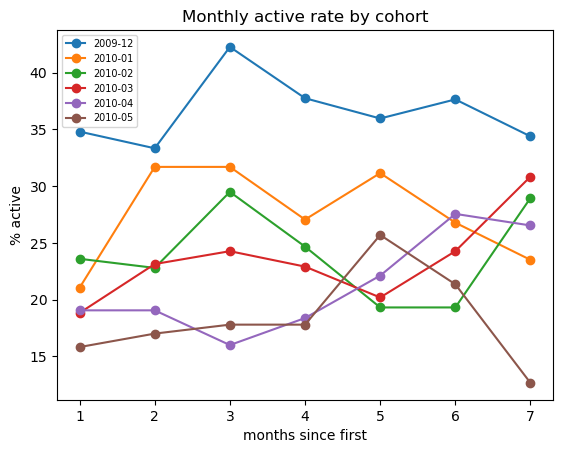

In [5]:
ev=events.copy(); first=ev.groupby(KEY)[T0].min().dt.to_period("M")
ev["cohort"]=ev[KEY].map(first); ev["pm"]=ev[T0].dt.to_period("M"); ev["off"]=ev["pm"].astype("int64")-ev["cohort"].astype("int64")
piv=ev.groupby(["cohort","off"])[KEY].nunique().unstack(); ret=piv.div(piv[0],axis=0)
display((ret.iloc[:8,1:8]*100).round(0))
plt.figure()
for c in ret.index[:6]: plt.plot(ret.columns[1:8], ret.loc[c].iloc[1:8]*100, marker="o", label=str(c))
plt.legend(fontsize=7); plt.title("Monthly active rate by cohort"); plt.xlabel("months since first"); plt.ylabel("% active"); plt.show()


## 4. Rolling multi-cutoff churn panel


cutoffs 16 | panel rows 47,813 | customers 5,204
per-cutoff churn% range: 38.0 - 62.3


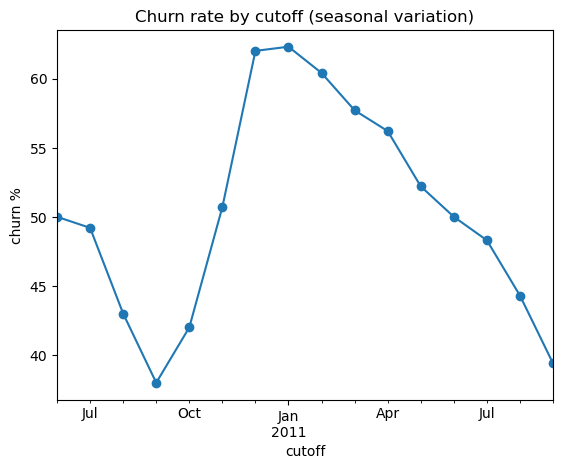

In [6]:
cuts=pd.date_range("2010-06-01", maxd-pd.Timedelta(days=HORIZON_DAYS), freq="MS")
evt=events[[KEY,T0]]; recs=[]
for T in cuts:
    ar=evt[(evt[T0]>T-pd.Timedelta(days=LOOKBACK))&(evt[T0]<=T)][KEY].unique()
    fut=set(evt[(evt[T0]>T)&(evt[T0]<=T+pd.Timedelta(days=HORIZON_DAYS))][KEY].unique())
    if len(ar)==0: continue
    recs.append(pd.DataFrame({KEY:ar,"cutoff":T,"churn":(~np.isin(ar,list(fut))).astype(int)}))
panel=pd.concat(recs,ignore_index=True)
rate=panel.groupby("cutoff")["churn"].mean().mul(100).round(1)
print(f"cutoffs {panel['cutoff'].nunique()} | panel rows {len(panel):,} | customers {panel[KEY].nunique():,}")
print("per-cutoff churn% range:",rate.min(),"-",rate.max())
plt.figure(); rate.plot(marker="o"); plt.title("Churn rate by cutoff (seasonal variation)"); plt.ylabel("churn %"); plt.show()


**Finding:** rolling cutoffs reduce single-date dependence and give ~48k rows (many more than a single snapshot). Per-cutoff churn swings 38–62% with the calendar.


## 5. Base rate + CI — Wilson vs customer-clustered bootstrap
The panel repeats each customer across cutoffs, so rows are **not** independent. Wilson (assumes independence) understates the CI; the clustered bootstrap (resamples customers) is the honest one.


In [7]:
k=int(panel["churn"].sum()); nn=len(panel)
print(f"pooled churn: {k}/{nn} = {k/nn*100:.1f}%")
print("repeat customers across >=2 cutoffs: {:.1f}%".format((panel.groupby(KEY)['cutoff'].nunique()>=2).mean()*100))
print("Wilson95 (independence-assumed, too narrow):", wilson(k,nn))
print("customer-clustered bootstrap95 (honest):", clustered_bootstrap_ci(panel, KEY, "churn"))


pooled churn: 24353/47813 = 50.9%
repeat customers across >=2 cutoffs: 96.3%
Wilson95 (independence-assumed, too narrow): (np.float64(50.49), np.float64(51.38))
customer-clustered bootstrap95 (honest): (np.float64(49.82), np.float64(52.08))


**Finding:** churn ~51% (balanced). Wilson width ~0.9pp is over-optimistic; clustered bootstrap ≈2pp (about 2× Wilson; bootstrap varies with B) is the real uncertainty. Report ROC-AUC **and** PR-AUC (baseline=prevalence) + lift vs base rate.


## 6. Horizon sensitivity — averaged across ALL cutoffs (not one date)


In [8]:
rows=[]
for h in [30,60,90,120,180]:
    cr=[]
    for T in cuts:
        ar=evt[(evt[T0]>T-pd.Timedelta(days=LOOKBACK))&(evt[T0]<=T)][KEY].unique()
        if len(ar)==0: continue
        fut=set(evt[(evt[T0]>T)&(evt[T0]<=T+pd.Timedelta(days=h))][KEY].unique())
        cr.append((~np.isin(ar,list(fut))).mean())
    rows.append({"H":h,"mean_churn_%":round(np.mean(cr)*100,1),"min":round(np.min(cr)*100,1),"max":round(np.max(cr)*100,1)})
display(pd.DataFrame(rows))


,H,mean_churn_%,min,max
0,30,73.8,63.6,82.2
1,60,59.6,47.0,70.9
2,90,50.4,38.0,62.3
3,120,44.1,34.1,55.9
4,180,36.9,28.5,46.7


**Finding:** churn falls smoothly as H grows, consistently across cutoffs — the label is not knife-edge sensitive to H. H=90 is a defensible mid-point.


## 7. MIN_PURCHASES reconsidered


In [9]:
for kk in [1,2,3]:
    keep=int((ppc>=kk).sum()); print(f"MIN_PURCHASES={kk}: keep {keep} ({keep/len(ppc)*100:.0f}%)")
print("Decision: do NOT pre-filter the churn label population (keep >=1). MIN_PURCHASES=2 only inside the sequence-based branch.")


MIN_PURCHASES=1: keep 5839 (100%)
MIN_PURCHASES=2: keep 4225 (72%)
MIN_PURCHASES=3: keep 3273 (56%)
Decision: do NOT pre-filter the churn label population (keep >=1). MIN_PURCHASES=2 only inside the sequence-based branch.


## 7.5 Customer revenue concentration (wholesale/enterprise mix check)


In [10]:
cr=events.groupby(KEY)["basket_value"].sum().sort_values(ascending=False)
ntop=max(1,int(np.ceil(len(cr)*0.01)))
print(f"top-1% customers ({ntop}) revenue share: {cr.head(ntop).sum()/cr.sum()*100:.1f}%")
print(f"top-10% revenue share: {cr.head(int(np.ceil(len(cr)*0.1))).sum()/cr.sum()*100:.1f}%")


top-1% customers (59) revenue share: 31.1%
top-10% revenue share: 63.1%


**Finding:** top-1% of customers ≈ 31% of revenue — the data mixes ordinary shoppers with wholesale/enterprise buyers. Consider a customer-type feature or robust scaling; don't delete.


## 8. Outliers — stats + example transaction rows


,col,mean,std,min,Q1,median,Q3,max,n_outlier_IQR,outlier_%
0,Quantity,13.04,72.31,1.00,2.00,6.00,12.00,19152.0,50064,6.50
1,Price,2.91,4.03,0.03,1.25,1.95,3.75,649.5,61879,8.03
2,line_revenue,21.20,65.10,0.06,4.95,11.90,19.50,8925.0,62109,8.06


Top-5 extreme Quantity records:


,Invoice,StockCode,Description,Quantity,Price,line_revenue
187845,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.1,1915.2
187829,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.1,1296.0
187831,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.1,1296.0
187828,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.1,1274.4
187830,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.1,1248.0


Top-5 extreme Price records:


,Invoice,StockCode,Description,Quantity,Price,line_revenue
374763,556444,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,649.5
80865,517650,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
80866,554836,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
104104,536835,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
126884,517393,22655,VINTAGE RED KITCHEN CABINET,2,295.0,590.0


Top-5 extreme line_revenue records:


,Invoice,StockCode,Description,Quantity,Price,line_revenue
749092,511465,15044A,PINK PAPER PARASOL,3500,2.55,8925.00
666096,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72
449101,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
460587,525968,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,1.66,5179.20
300868,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00


Top-5 extreme basket_value records:


,Customer ID,Invoice,event_time,n_items,basket_qty,basket_value
11021,14156,493819,2010-01-07 12:34:00,93,24568,43555.10
30976,17450,524181,2010-09-27 16:59:00,13,8172,33167.80
31006,17450,567423,2011-09-20 11:05:00,11,11816,27872.80
35320,18102,526934,2010-10-14 09:46:00,15,5079,26007.08
35296,18102,515944,2010-07-15 15:29:00,17,4992,22863.36


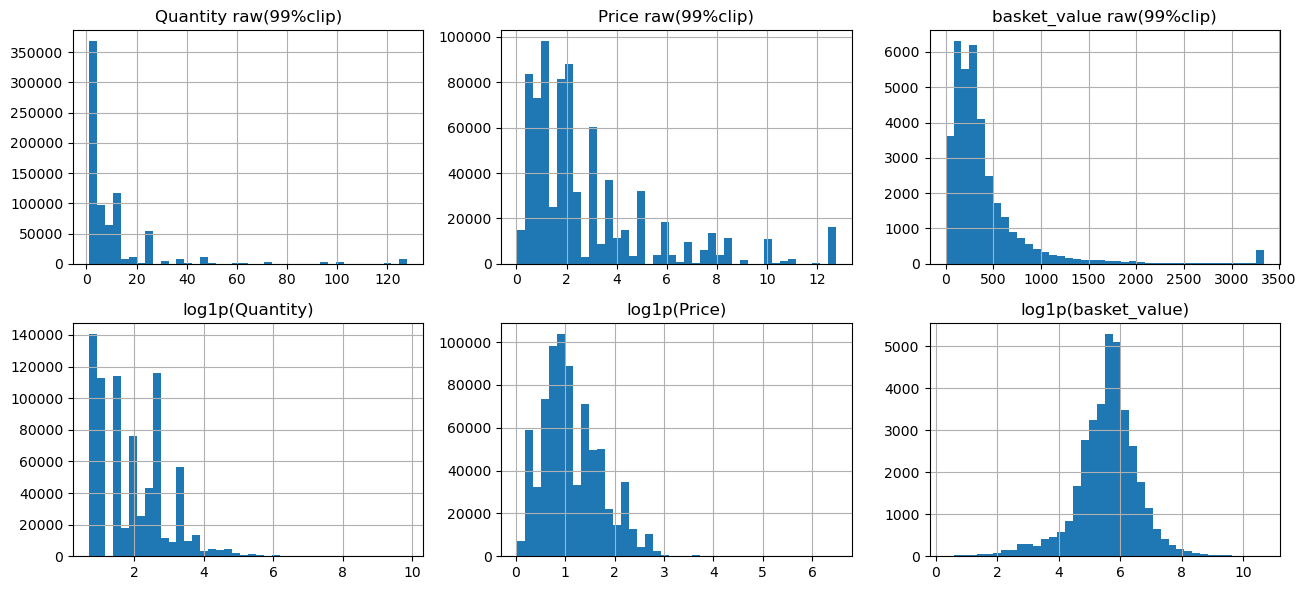

In [11]:
display(outlier_table(lines,[QTY,PRICE,"line_revenue"]))
line_cols=[INVOICE,STOCK,"Description",QTY,PRICE,"line_revenue"]
evt_cols=[KEY,INVOICE,"event_time","n_items","basket_qty","basket_value"]
for col,src,cols in [(QTY,lines,line_cols),(PRICE,lines,line_cols),("line_revenue",lines,line_cols),("basket_value",events,evt_cols)]:
    print(f"Top-5 extreme {col} records:"); display(src.nlargest(5,col)[cols])
fig,ax=plt.subplots(2,3,figsize=(13,6))
for j,(df,col) in enumerate([(lines,QTY),(lines,PRICE),(events,"basket_value")]):
    s=df[col]; assert s.min()>=0, f"{col} has negative values"   # assertion instead of clip(lower=0)
    s.clip(upper=s.quantile(.99)).hist(bins=40,ax=ax[0,j]); ax[0,j].set_title(f"{col} raw(99%clip)")
    np.log1p(s).hist(bins=40,ax=ax[1,j]); ax[1,j].set_title(f"log1p({col})")
plt.tight_layout(); plt.show()


**Decision:** heavy-tailed -> log1p at modeling; XGBoost robust; no deletion. Extreme rows are reviewed examples appear legitimate (bulk orders), not errors.


## 9. Seasonality — orders, revenue, active customers, avg basket (complete months)


dropped partial months: 2009-12-01 and 2011-12-01


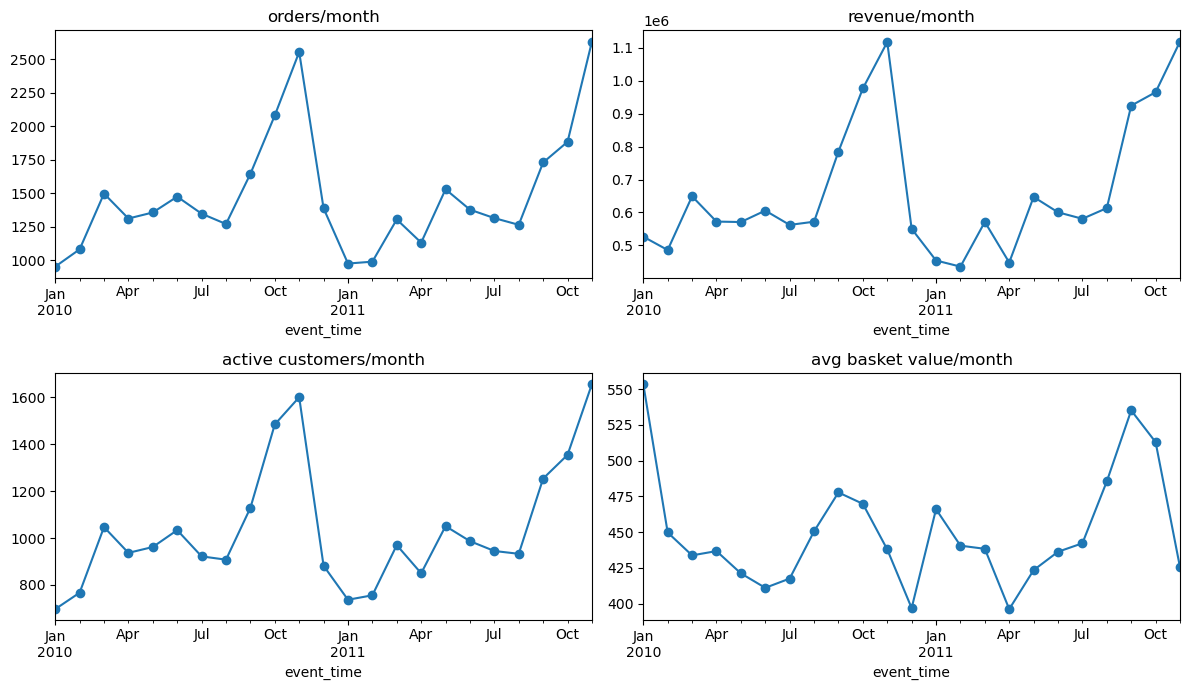

peak orders month: 2011-11-01
peak revenue month: 2011-11-01
peak active_customers month: 2011-11-01
peak avg_basket month: 2010-01-01


In [12]:
m=events.set_index(T0).resample("MS").agg(orders=("Invoice","size"),revenue=("basket_value","sum"),
        active_customers=(KEY,"nunique"),avg_basket=("basket_value","mean"))
full=m.iloc[1:-1]  # drop partial first/last
print("dropped partial months:", m.index[0].date(),"and",m.index[-1].date())
fig,ax=plt.subplots(2,2,figsize=(12,7))
full["orders"].plot(ax=ax[0,0],marker="o",title="orders/month")
full["revenue"].plot(ax=ax[0,1],marker="o",title="revenue/month")
full["active_customers"].plot(ax=ax[1,0],marker="o",title="active customers/month")
full["avg_basket"].plot(ax=ax[1,1],marker="o",title="avg basket value/month")
plt.tight_layout(); plt.show()
for c in ["orders","revenue","active_customers","avg_basket"]:
    print(f"peak {c} month:", full[c].idxmax().date())


**Finding:** orders/revenue/active-customers peak in Q4 (Nov 2011); **avg basket peaks Jan 2010** (post-holiday) — a different pattern. Add month & seasonality features.


## 10. Leakage-safe split demonstration
Two leakage axes: **identity** (a customer repeats across cutoffs) and **time**. Below shows both.


In [13]:
from sklearn.model_selection import GroupShuffleSplit
# (i) customer-grouped (identity leakage)
gss=GroupShuffleSplit(n_splits=1,test_size=0.25,random_state=RANDOM_SEED)
tr,te=next(gss.split(panel,groups=panel[KEY])); train,test=panel.iloc[tr],panel.iloc[te]
print("[customer-grouped] train",len(train),"test",len(test),"| customer overlap:",len(set(train[KEY])&set(test[KEY])))
# (ii) time-based (train on earlier cutoffs, test on latest)
split_T=sorted(panel["cutoff"].unique())[-4]
tr2=panel[panel["cutoff"]<split_T]; te2=panel[panel["cutoff"]>=split_T]
print(f"[time-based] train cutoffs < {pd.Timestamp(split_T).date()} ({len(tr2)}), test >= ({len(te2)}) | train churn {tr2['churn'].mean()*100:.1f}% test {te2['churn'].mean()*100:.1f}%")
print("04_model will report TWO SEPARATE evaluations: (a) temporal (train past cutoffs, test future) and (b) customer-disjoint (no shared customers) — reported separately, not merged.")


[customer-grouped] train 35941 test 11872 | customer overlap: 0
[time-based] train cutoffs < 2011-06-01 (36919), test >= (10894) | train churn 52.6% test 45.4%
04_model will report TWO SEPARATE evaluations: (a) temporal (train past cutoffs, test future) and (b) customer-disjoint (no shared customers) — reported separately, not merged.


## 11. K-means RFM segmentation
⚠️ **This full-period RFM segmentation is EXPLORATORY ONLY and MUST NOT be used as a predictive feature** — it uses data up to `maxd` (future w.r.t. any cutoff). If segments are ever used as features, recompute RFM as-of each cutoff (only pre-cutoff data) and fit the scaler on train only.


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
rfm=events.groupby(KEY).agg(recency=(T0,lambda s:(maxd-s.max()).days),frequency=("Invoice","size"),monetary=("basket_value","sum"))
assert (rfm.values>=0).all(), "RFM has negative values"
X=StandardScaler().fit_transform(np.log1p(rfm))
for k in [3,4,5]: print(f"k={k}: silhouette={silhouette_score(X,KMeans(n_clusters=k,random_state=RANDOM_SEED,n_init=10).fit_predict(X)):.3f}")
rfm["seg"]=KMeans(n_clusters=4,random_state=RANDOM_SEED,n_init=10).fit_predict(X)
display(rfm.groupby("seg").agg(n=("frequency","size"),recency=("recency","median"),frequency=("frequency","median"),monetary=("monetary","median")).round(1))


k=3: silhouette=0.348
k=4: silhouette=0.361
k=5: silhouette=0.338


,n,recency,frequency,monetary
seg,,,,
0,1993,397.0,1.0,267.2
1,1206,22.0,3.0,718.2
2,1145,15.0,13.0,4964.0
3,1495,173.0,5.0,1449.1


**Finding:** distinct RFM segments (loyal / lapsing / one-time) — exploratory only per the warning above.


## Decisions summary v3 -> feature stage

| topic | decision |
|---|---|
| positive class | churn = at-risk (prior 180d) customer, no purchase in next 90d |
| sampling | rolling monthly cutoffs (~48k panel rows) |
| base rate & CI | ~51% churn; **customer-clustered bootstrap CI (≈2pp (about 2× Wilson; bootstrap varies with B))**, not Wilson (~0.9pp, too narrow) |
| metrics (04_model, via ds_common.evaluate_classifier) | ROC-AUC + PR-AUC(baseline=prevalence) + P/R/F1@thr + confusion + Precision@k/Recall@k/Lift@k + Brier + LogLoss + ECE + calibration |
| gap | per-customer median ~57d |
| min history | keep >=1 for label; MIN_PURCHASES=2 only in sequence-based branch |
| skew | log1p; no deletion |
| concentration | top-1% ≈ 31% revenue -> customer-type/robust handling |
| geography | ~90% UK (raw ~92%) |
| split | customer-grouped **and** time-forward — reported separately at 04_model |
| K-means | exploratory only; forbidden as predictive feature unless recomputed as-of cutoff |
